# Classificação de batimentos cardíacos: avaliação honesta por paciente

Projeto final da Trilha de Trainees Insper AI (Tom e Renata).

**Pergunta:** quanto do desempenho "bonito" (~98-99%) de classificadores de arritmia some quando o teste usa pacientes que o modelo nunca viu, principalmente na classe S? E o que ajuda a recuperar parte dessa queda?

**Como ler:** cada seção tem o título numa célula separada. No VS Code dá para recolher a seção e ver só os títulos. O plano completo e o log de decisões estão no `CLAUDE.md`.

## 0. Status do projeto

Atualizar sempre que uma etapa mudar.

| Seção | Status |
|---|---|
| 1. Configuração | Pronto, rodado |
| 2. Teste de leitura (gravação 100) | Pronto, rodado (05/11) |
| 3. Montagem do dataset | A fazer (constantes prontas) |
| 4. EDA | A fazer |
| 5. Divisão dos dados | A fazer |
| 6. Experimentos E0-E5 | A fazer |
| 7. Análise de erros | A fazer |
| 8. Conclusões | A fazer |

## 1. Configuração

Instala o `wfdb` se precisar (biblioteca do PhysioNet para ler os arquivos de ECG), importa as bibliotecas e fixa as seeds para que os resultados se repitam a cada execução. A seed do TensorFlow é fixada na seção de experimentos, quando ele for importado.

In [1]:
# Instala o wfdb só se ele não existir (ex.: no Colab). Instalar sem precisar
# pode atualizar numpy/pandas e quebrar outros pacotes do ambiente local.
try:
    import wfdb
except ImportError:
    %pip install -q wfdb

In [2]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DADOS_DIR = "mitdb"  # pasta onde as gravações do MIT-BIH são salvas

## 2. Teste de leitura dos dados (gravação 100)

Antes de montar o dataset, confirmamos que conseguimos baixar uma gravação, ler o sinal e ler as anotações dos cardiologistas (posição e tipo de cada batimento).

- Cada gravação tem um arquivo de sinal (`rdrecord`) e um de anotações `.atr` (`rdann`).
- Escolhemos o canal pelo **nome** (`MLII`), e não pela posição, porque a ordem das derivações pode mudar entre gravações.
- Nem toda anotação é um batimento: alguns símbolos (como `+`) marcam mudança de ritmo. Na montagem do dataset vamos manter só os símbolos de batimento.

In [3]:
wfdb.dl_database("mitdb", dl_dir=DADOS_DIR, records=["100"])

registro = wfdb.rdrecord(f"{DADOS_DIR}/100")
anotacao = wfdb.rdann(f"{DADOS_DIR}/100", "atr")

print("Frequência (Hz):", registro.fs)
print("Derivações:", registro.sig_name)
print("Formato do sinal (amostras, canais):", registro.p_signal.shape)
print("Primeiras posições anotadas:", anotacao.sample[:10])
print("Primeiros símbolos:", anotacao.symbol[:10])

Generating record list for: 100
Generating list of all files for: 100


Created local base download directory: mitdb


Finished downloading files
Frequência (Hz): 360
Derivações: ['MLII', 'V5']
Formato do sinal (amostras, canais): (650000, 2)
Primeiras posições anotadas: [  18   77  370  662  946 1231 1515 1809 2044 2402]
Primeiros símbolos: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


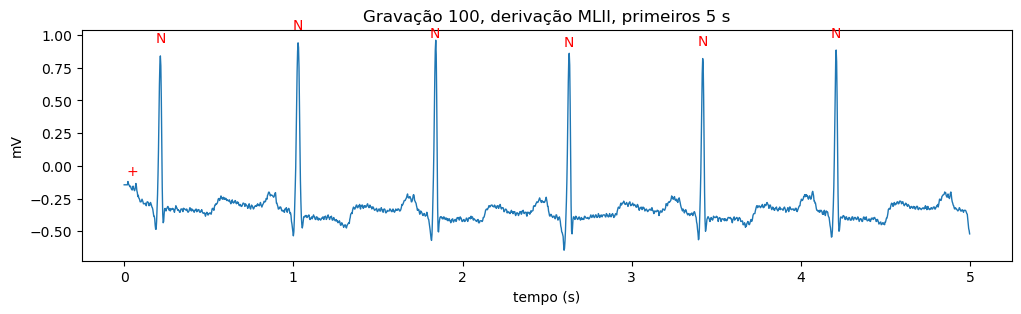

In [4]:
# Plota os primeiros 5 segundos da MLII com o símbolo de cada anotação
fs = registro.fs
canal = registro.sig_name.index("MLII")
n = 5 * fs
t = np.arange(n) / fs
sinal = registro.p_signal[:n, canal]

dentro = anotacao.sample < n
posicoes = anotacao.sample[dentro]
simbolos = np.array(anotacao.symbol)[dentro]

plt.figure(figsize=(12, 3))
plt.plot(t, sinal, lw=1)
for pos, simbolo in zip(posicoes, simbolos):
    plt.text(pos / fs, sinal[pos] + 0.1, simbolo, ha="center", color="red")
plt.xlabel("tempo (s)")
plt.ylabel("mV")
plt.title("Gravação 100, derivação MLII, primeiros 5 s")
plt.show()

In [5]:
# Quantas anotações de cada símbolo existem na gravação inteira
Counter(anotacao.symbol)

Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})

**Resultado do teste (05/11):** a leitura funciona. O sinal tem 360 Hz e duas derivações (MLII e V5), e cada anotação cai em cima do pico R, então dá para usar `anotacao.sample` como centro da janela de cada batimento. A gravação 100 tem 2.239 batimentos N, 33 A (classe S) e 1 V; o `+` é marca de ritmo e será descartado.

## 3. Montagem do dataset

Montamos uma tabela com **uma linha por batimento**: `paciente`, `classe` (N/S/V/F/Q), `sinal` (janela ao redor do pico R) e, depois, `rr_anterior` / `rr_posterior`. A mesma tabela é usada nos dois tipos de split.

Abaixo ficam as constantes do plano: o mapeamento dos símbolos para as classes AAMI e as listas DS1/DS2 de de Chazal et al. (2004). O mapeamento ainda precisa ser **conferido na documentação do PhysioNet**.

**A fazer:** decidir a janela ao redor do pico R e a normalização, depois cortar os batimentos de todas as gravações.

In [6]:
# Símbolo do MIT-BIH -> classe AAMI EC57 (a conferir no PhysioNet)
MAPA_AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q",
}

# Gravações com marcapasso, excluídas do split por paciente
MARCAPASSO = ["102", "104", "107", "217"]

# Split por paciente de de Chazal et al. (2004)
DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]  # treino
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]  # teste

assert len(DS1) == 22 and len(DS2) == 22 and not set(DS1) & set(DS2)

## 4. Análise exploratória (EDA)

Contagem de batimentos por classe (no total, no DS1 e no DS2), batimento médio de cada classe e quantos batimentos S cada paciente do DS2 tem. Esse último ponto mostra se a classe S depende de poucos pacientes.

**A fazer.**

## 5. Divisão dos dados

O ponto central do projeto. Fazemos dois splits da mesma tabela:

- **Aleatório por batimento:** batimentos do mesmo paciente caem no treino e no teste. É o que gera os resultados "bonitos".
- **Por paciente (DS1 → DS2):** o teste só tem pacientes que o modelo nunca viu. É o cenário real de um hospital.

A validação também é separada **por paciente**, dentro do DS1. Normalização, oversampling e escolha de hiperparâmetros usam só o treino.

**A fazer.**

## 6. Experimentos

Mudamos uma coisa por vez. As métricas principais são recall, precision e F1 **por classe** e o F1 macro. Acurácia geral aparece só como referência, porque ~83% dos batimentos são N.

**Tabela de experimentos** (preencher só com resultados rodados):

| Exp. | Configuração | Split | Recall S | Recall V | Recall F | F1 macro |
|---|---|---|---|---|---|---|
| E0 | Sempre "N" | por paciente | - | - | - | - |
| E1 | MLP | aleatório | - | - | - | - |
| E2 | MLP | por paciente | - | - | - | - |
| E3 | E2 + peso por classe | por paciente | - | - | - | - |
| E4 | E2 + oversampling (só treino) | por paciente | - | - | - | - |
| E5 | E2 + intervalo RR | por paciente | - | - | - | - |

### E0. Baseline "sempre N"

Mostra que uma acurácia alta não quer dizer nada aqui: chutar sempre "N" já acerta a maioria e erra todas as arritmias. **A fazer.**

### E1. MLP com split aleatório

Reproduz o resultado "bonito" da literatura. **A fazer.**

### E2. MLP com split por paciente

A mesma MLP do E1, agora avaliada em pacientes novos. A diferença entre E1 e E2 é o resultado principal do projeto. **A fazer.**

### E3. Peso por classe

Errar um batimento raro (S, V, F) passa a custar mais na loss do que errar um N. **A fazer.**

### E4. Oversampling

Repete batimentos das classes raras, **só no treino e depois do split**. **A fazer.**

### E5. Intervalo RR como entrada

Um batimento S costuma chegar antes do esperado, e o formato da onda sozinho não mostra isso. Adicionamos o tempo até o batimento anterior e até o próximo. **A fazer.**

## 7. Análise de erros (classe S)

Onde a classe S falha: matriz de confusão, desempenho por paciente do DS2 e exemplos de batimentos S classificados como N. **A fazer.**

## 8. Conclusões e limitações

**A fazer**, depois dos experimentos.

## Bônus

Só se o núcleo estiver pronto. Candidatos: Conv1D, Grad-CAM/saliency (não visto nas aulas), focal loss, teste no INCART.